# Deep learning for healthcare, session 3
# Where deep learning earns its place: images, and the test-set trap

**Question for today:** for skin lesion photos, does a small neural network improve on a simple model, and does the test give a fair assessment?

Sessions 1 and 2 found no clear gain from a neural network on intensive care unit (ICU) summary data. Images contain shapes, borders and colour patterns spread across many pixels. We now test whether a network can learn useful patterns from those pixels

| Part | What we do | Approx. time |
|---|---|---|
| 1 | Meet the data and audit who is in it | 15 min |
| 2 | A simple baseline: logistic regression on raw pixels | 10 min |
| 3 | How convolution sees an image, then train a small network | 20 min |
| 4 | Is the test really independent? Duplicates and case mix (4.1 can run as optional, saved outputs shown) | 20 min |
| 5 | Check changes to training images | 10 min |
| 6 | Takeaways | 5 min |

**Responsible artificial intelligence (AI) questions today:** question 1, *what does it use?*, and question 3, *who does it miss?*, start with the data, before any model

## Setup

Locally: create and activate the Conda environment in `environment.yml` as described in the README. Data (about 40 MB) downloads automatically the first time into a `data` folder

In [1]:
# Setup: libraries, reproducibility, plot style
import warnings, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED, ORANGE = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b", "#f28e2b"

In [2]:
# Data: DermaMNIST (original and corrected) from the authors' public repository, cached in ./data
BASE = "https://raw.githubusercontent.com/kakumarabhishek/Corrected-Skin-Image-Datasets/main/DermaMNIST/DermaMNIST_Analysis/"
FILES = {"corrected": "NPZ_files/dermamnist_corrected_28.npz",
         "original": "NPZ_files/dermamnist_original.npz",
         "meta_corrected": "CSV_files/combined_metadata_corrected-HAM10000_corrected.csv",
         "split_original": "dermamnist_split_info.csv",
         "ham_meta": "HAM10000_metadata.csv"}
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
def fetch(key):
    path = DATA_DIR / Path(FILES[key]).name
    if not path.exists():
        print("downloading", path.name); urllib.request.urlretrieve(BASE + FILES[key], path)
    return path

CLASSES = {0: "Actinic keratosis (akiec)", 1: "Basal cell carcinoma (bcc)", 2: "Benign keratosis (bkl)",
           3: "Dermatofibroma (df)", 4: "Melanoma (mel)", 5: "Common mole (nv)", 6: "Vascular lesion (vasc)"}
# Actinic keratosis: a rough sun-damage patch that can turn into skin cancer; the group also includes very early skin cancer
CANCER_GROUP = [0, 1, 4]          # possibly cancerous: refer to a dermatologist

def load_split(key):
    d = np.load(fetch(key))
    return {s: {"X": d[f"{s}_images"], "cls": d[f"{s}_labels"].ravel(),
                "y": np.isin(d[f"{s}_labels"].ravel(), CANCER_GROUP).astype(np.float32)} for s in ["train", "val", "test"]}

def load_corrected_with_meta():
    data = load_split("corrected")
    meta = pd.read_csv(fetch("meta_corrected"))          # rows are in the same order as the images within each split
    for s in data:
        data[s]["meta"] = meta[meta.split == s].reset_index(drop=True)
    return data

# 1. The data and who is in it

| Dataset | What it contains | Source |
|---|---|---|
| **HAM10000** | 10,015 dermatoscope images from 7,470 skin lesions, collected in Vienna, Austria, and Queensland, Australia | [Tschandl et al., 2018](https://doi.org/10.1038/sdata.2018.161) |
| **DermaMNIST** | HAM10000 images reduced to 28 x 28 pixels for teaching and model comparisons | [Yang et al., 2023](https://doi.org/10.1038/s41597-022-01721-8) |
| **DermaMNIST corrected** | Images regrouped so photos of the same lesion stay in the same split, with additional fixes for duplicate images and lesion identifiers | [Abhishek et al., 2025](https://doi.org/10.1038/s41597-025-04382-5), [data repository](https://github.com/kakumarabhishek/Corrected-Skin-Image-Datasets) |

A **skin lesion** is an area of skin that differs from the skin around it. A **dermatoscope** is a magnifying device with its own light, used to examine skin lesions. These are dermatoscope images, not ordinary phone photos

> **Image limit:** reducing images to 28 x 28 pixels removes much of the detail doctors use. This keeps the exercise quick to run; it is not evidence that such small images are suitable for clinical use

**Split limit:** the corrected data separate lesions, not necessarily patients. The metadata do not identify patients, so we cannot check whether different lesions from one patient appear in different splits

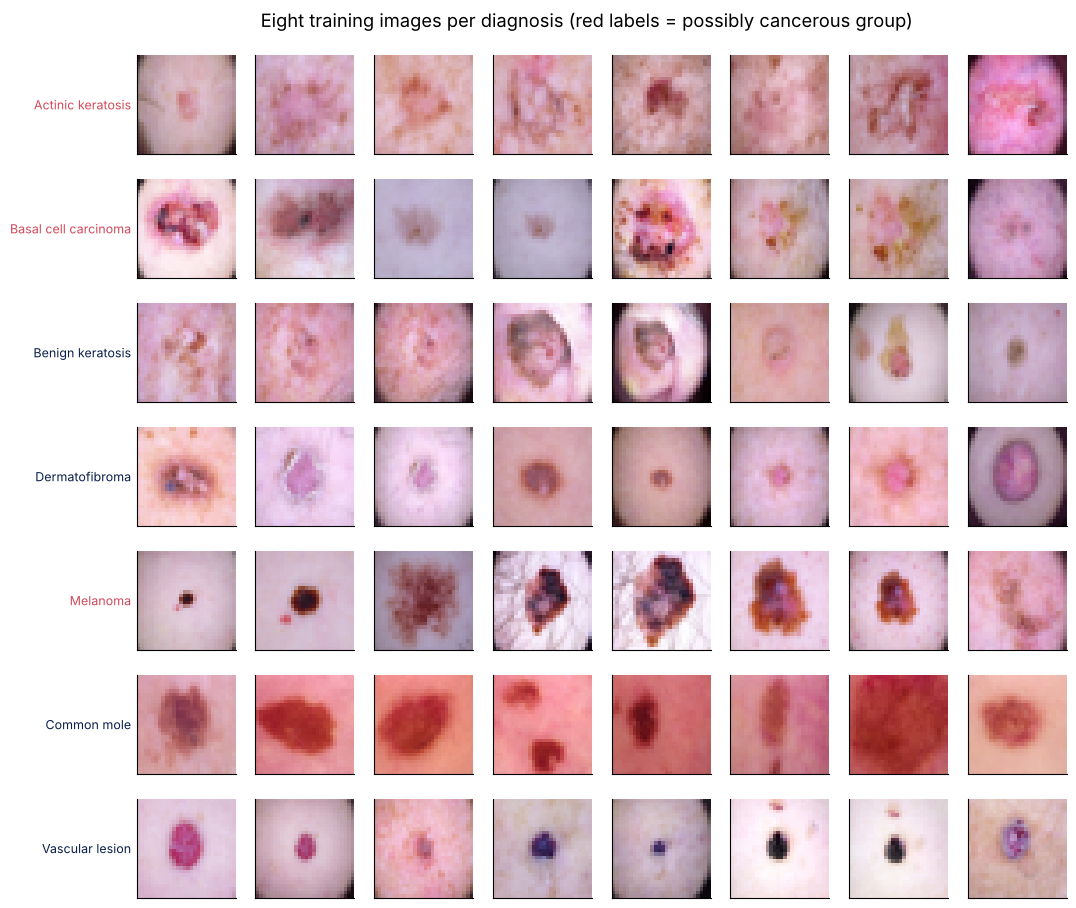

In [3]:
data = load_corrected_with_meta()
X, cls, meta = data["train"]["X"], data["train"]["cls"], data["train"]["meta"]
fig, axes = plt.subplots(7, 8, figsize=(12, 11))
for r in range(7):
    idx = np.where(cls == r)[0][:8]
    for c, i in enumerate(idx):
        ax = axes[r, c]; ax.imshow(X[i]); ax.set_xticks([]); ax.set_yticks([])
        if c == 0: ax.set_ylabel(CLASSES[r].split(" (")[0], rotation=0, ha="right", va="center", fontsize=9,
                                 color=RED if r in CANCER_GROUP else NAVY)
fig.suptitle("Eight training images per diagnosis (red labels = possibly cancerous group)", y=0.92)
plt.show()

**What this shows**

- At 28 x 28 pixels, some colour, shape and border differences remain visible, but much detail is lost
- We combine the seven diagnoses into two groups for this exercise
- **Possibly cancerous:** melanoma, basal cell carcinoma, and a combined category containing actinic keratosis, a precancerous patch, and very early skin cancer
- **Benign:** common moles, benign keratosis, dermatofibroma and vascular lesions

A positive label means the image belongs to our "possibly cancerous" group. It does not mean every positive lesion is cancer, or that every benign lesion can safely be left without review

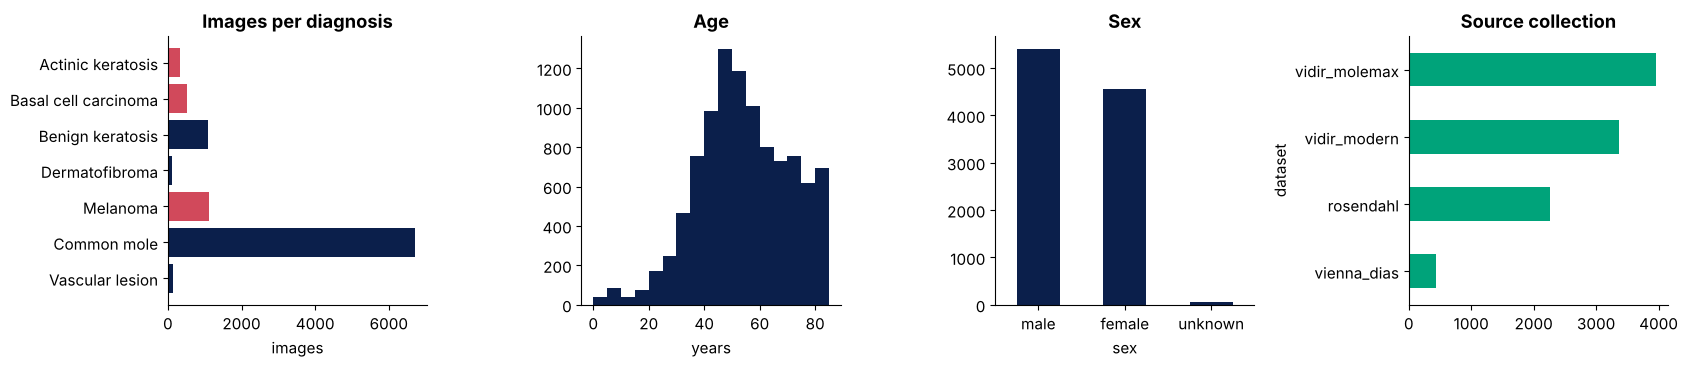

Share possibly cancerous per split: {'train': '21.2%', 'val': '11.0%', 'test': '12.1%'}
Skin tone recorded: no column exists in the metadata -> ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset', 'split', 'set']


In [4]:
allmeta = pd.concat([data[s]["meta"].assign(set=s) for s in data])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
counts = pd.Series(np.concatenate([data[s]["cls"] for s in data])).value_counts().sort_index()
axes[0].barh([CLASSES[k].split(" (")[0] for k in counts.index], counts.values,
             color=[RED if k in CANCER_GROUP else NAVY for k in counts.index]); axes[0].invert_yaxis()
axes[0].set_title("Images per diagnosis"); axes[0].set_xlabel("images")
axes[1].hist(allmeta.age.dropna(), bins=range(0, 90, 5), color=NAVY); axes[1].set_title("Age"); axes[1].set_xlabel("years")
allmeta.sex.value_counts().plot.bar(ax=axes[2], color=NAVY, rot=0); axes[2].set_title("Sex")
allmeta.dataset.value_counts().plot.barh(ax=axes[3], color=GREEN); axes[3].set_title("Source collection"); axes[3].invert_yaxis()
plt.tight_layout(); plt.show()
share = {s: f"{100*data[s]['y'].mean():.1f}%" for s in data}
print("Share possibly cancerous per split:", share)
print("Skin tone recorded: no column exists in the metadata ->", [c for c in allmeta.columns])

**What this shows**

- **Unequal group sizes:** about two thirds of the images are common moles. The possibly cancerous group is much smaller
- **Who is represented:** mostly middle-aged and older adults, slightly more men, from four source collections in two locations
- **What we cannot check:** skin tone was not recorded. We cannot identify skin-tone groups or compare their model results

> **Data question:** who is represented, who is missing, and what was never recorded? Missing skin-tone information leaves performance across skin tones unknown

# 2. A simple baseline: logistic regression on pixels

Each image has 28 x 28 x 3 = 2,352 numbers (red, green and blue brightness of each pixel). Logistic regression can use them directly: one weight per pixel and colour. Because the weights sit on the image grid, we can draw the weights. A map with 2,352 weights is still too large to explain every prediction at a glance

Pixel logistic regression, test AUROC 0.875


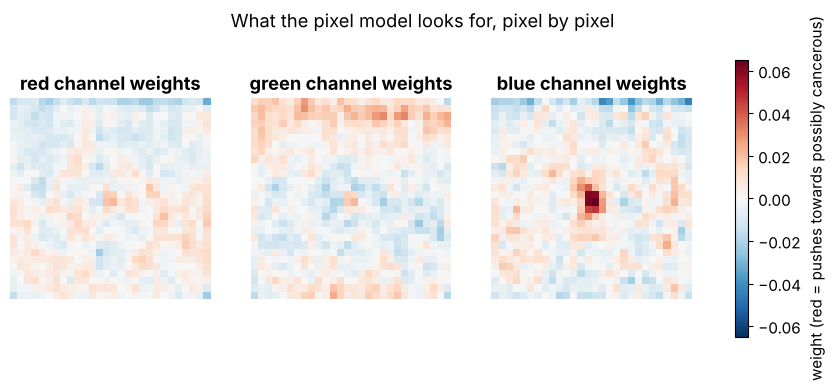

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
flat = {s: data[s]["X"].reshape(len(data[s]["X"]), -1) / 255.0 for s in data}
sc = StandardScaler().fit(flat["train"])
pix = LogisticRegression(C=0.001, max_iter=3000).fit(sc.transform(flat["train"]), data["train"]["y"])
p_pix = pix.predict_proba(sc.transform(flat["test"]))[:, 1]
print(f"Pixel logistic regression, test AUROC {roc_auc_score(data['test']['y'], p_pix):.3f}")

w = pix.coef_.reshape(28, 28, 3)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for k, name in enumerate(["red", "green", "blue"]):
    v = np.abs(w).max(); im = axes[k].imshow(w[:, :, k], cmap="RdBu_r", vmin=-v, vmax=v)
    axes[k].set_title(f"{name} channel weights"); axes[k].axis("off")
fig.colorbar(im, ax=axes, label="weight (red = pushes towards possibly cancerous)")
fig.suptitle("What the pixel model looks for, pixel by pixel", y=1.02); plt.show()

**What this shows** (output above)

- Logistic regression on pixels scores 0.875 on the **area under the receiver operating characteristic curve (AUROC)**. This measures ranking: 0.5 means chance-level ranking; 1.0 means perfect ranking
- Strong positive weights appear in the centre of the blue channel. Higher blue-channel values there increase this model's prediction when other pixel values stay the same
- Some strong weights also appear at the image edges. These could reflect lighting, the device frame or other image patterns. The weights alone do not establish which explanation is correct

> **Practical check:** even a simple model can use unexpected image patterns. Drawing its weights helps us decide what to investigate

# 3. How a convolutional network processes an image

A **convolution** slides a small set of weights, called a **filter**, across an image. At each position, it multiplies the nearby pixel values by those weights and adds the results

Our hand-made examples use a grey-scale image and 3 x 3 filters, so each has 9 weights. A colour filter also has weights for each colour channel. Reusing the same filter across positions lets it detect a similar local pattern in different places

A **convolutional neural network (CNN)** learns its filters from training data. The examples below show the idea using filters we choose ourselves

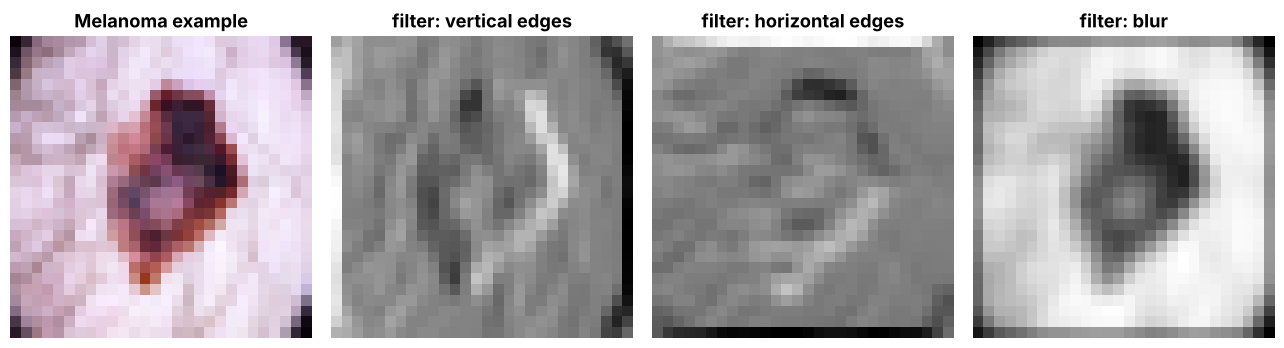

In [6]:
import torch.nn.functional as F
img = data["train"]["X"][np.where(data["train"]["cls"] == 4)[0][3]]
gray = torch.tensor(img.mean(2) / 255.0, dtype=torch.float32)[None, None]
filters = {"vertical edges": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
           "horizontal edges": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
           "blur": [[1 / 9] * 3] * 3}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(img); axes[0].set_title("Melanoma example"); axes[0].axis("off")
for ax, (name, k) in zip(axes[1:], filters.items()):
    out = F.conv2d(gray, torch.tensor(k, dtype=torch.float32)[None, None], padding=1)[0, 0]
    ax.imshow(out, cmap="gray"); ax.set_title(f"filter: {name}"); ax.axis("off")
plt.tight_layout(); plt.show()

**What this shows:** the edge filters highlight changes in brightness, while the blur filter smooths them. A trained network learns filters that help its prediction task. Our network produces 16 maps, then 32, then 64. Two pooling steps reduce the map width from 28 to 14 to 7 pixels, allowing later layers to combine information from larger parts of the original image

In [7]:
# A small convolutional neural network (CNN) and its training loop
class SmallCNN(nn.Module):
    """Three convolution blocks, then average over the image and one output neuron"""
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),   # 28x28 -> 14x14
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  # 14x14 -> 7x7
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU())                   # 64 maps of 7x7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x))

def to_tensor(X, mu, sd):
    """uint8 images (n, 28, 28, 3) -> normalised float tensor (n, 3, 28, 28)"""
    return torch.tensor(((X / 255.0 - mu) / sd).transpose(0, 3, 1, 2), dtype=torch.float32)

def augment(x):
    """Label-preserving changes for dermoscopy: mirror and rotate by 90 degree steps"""
    if np.random.rand() < 0.5: x = x.flip(3)
    if np.random.rand() < 0.5: x = x.flip(2)
    return torch.rot90(x, np.random.randint(4), (2, 3))

def predict_cnn(model, T, batch=1024):
    model.eval()
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(model(T[i:i + batch])).numpy().ravel() for i in range(0, len(T), batch)])

def train_cnn(Xtr, ytr, Xva, yva, epochs=15, use_augment=True, seed=0, verbose=True):
    """Adam, batches of 128, keep the epoch with the best validation AUROC. Returns model, normalisation and history"""
    np.random.seed(seed); torch.manual_seed(seed)
    mu, sd = (Xtr / 255.0).mean((0, 1, 2)), (Xtr / 255.0).std((0, 1, 2))
    Ttr, Tva, yt = to_tensor(Xtr, mu, sd), to_tensor(Xva, mu, sd), torch.tensor(ytr)
    model = SmallCNN(); opt = torch.optim.Adam(model.parameters(), lr=1e-3); lossf = nn.BCEWithLogitsLoss()
    hist, best, state, t0 = [], -1, None, time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(yt)); tot = 0
        for i in range(0, len(yt), 128):
            b = perm[i:i + 128]; x = augment(Ttr[b]) if use_augment else Ttr[b]
            opt.zero_grad(); loss = lossf(model(x).squeeze(1), yt[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        auc = roc_auc_score(yva, predict_cnn(model, Tva))
        hist.append({"epoch": ep + 1, "train_loss": tot / len(yt), "val_auroc": auc})
        if auc > best: best, state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state); model.eval()
    if verbose: print(f"trained {epochs} epochs in {time.time() - t0:.0f} s, best validation AUROC {best:.3f}")
    return model, (mu, sd), pd.DataFrame(hist)

trained 15 epochs in 21 s, best validation AUROC 0.960


Parameters: pixel logistic regression 2,353 | CNN 23,873
Test set: 1227 images from 1149 lesions


Test AUROC: pixels + logistic 0.875 | CNN 0.944 | gap +0.069, 95% CI +0.045 to +0.093


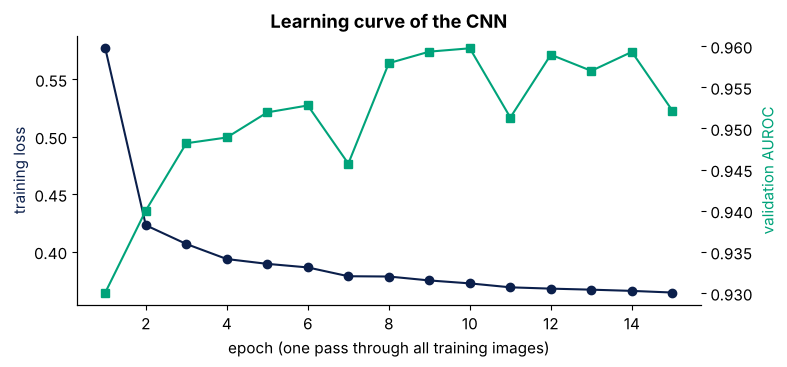

In [8]:
model, (mu, sd), hist = train_cnn(data["train"]["X"], data["train"]["y"], data["val"]["X"], data["val"]["y"], seed=0)
T = {s: to_tensor(data[s]["X"], mu, sd) for s in data}
p_cnn = predict_cnn(model, T["test"]); yte = data["test"]["y"]
print(f"Parameters: pixel logistic regression {pix.coef_.size + 1:,} | CNN {sum(q.numel() for q in model.parameters()):,}")

# Lesion-level bootstrap: resample lesions, not images, because a few test lesions have more than one photo
rng = np.random.default_rng(0)
les = data["test"]["meta"].lesion_id.values; uniq = np.unique(les); rows_of = {g: np.where(les == g)[0] for g in uniq}
print(f"Test set: {len(yte)} images from {len(uniq)} lesions")
B = [np.concatenate([rows_of[g] for g in rng.choice(uniq, len(uniq))]) for _ in range(2000)]
gaps = [roc_auc_score(yte[b], p_cnn[b]) - roc_auc_score(yte[b], p_pix[b]) for b in B]
print(f"Test AUROC: pixels + logistic {roc_auc_score(yte, p_pix):.3f} | CNN {roc_auc_score(yte, p_cnn):.3f} | "
      f"gap {roc_auc_score(yte, p_cnn) - roc_auc_score(yte, p_pix):+.3f}, 95% CI {np.percentile(gaps, 2.5):+.3f} to {np.percentile(gaps, 97.5):+.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8)); ax2 = ax.twinx()
ax.plot(hist.epoch, hist.train_loss, "o-", color=NAVY, label="training loss"); ax.set_ylabel("training loss", color=NAVY)
ax2.plot(hist.epoch, hist.val_auroc, "s-", color=GREEN, label="validation AUROC"); ax2.set_ylabel("validation AUROC", color=GREEN)
ax.set_xlabel("epoch (one pass through all training images)"); ax.set_title("Learning curve of the CNN"); plt.tight_layout(); plt.show()

# Save for sessions 4 and 5
Path("models").mkdir(exist_ok=True)
torch.save({"state": model.state_dict(), "mu": mu, "sd": sd, "data": "dermamnist_corrected_28.npz", "seed": 0, "torch": torch.__version__}, "models/cnn_corrected_seed0.pt")

**What this shows** (output above)

- The CNN scores 0.944 AUROC, compared with 0.875 for pixel logistic regression. The difference is +0.069, with a 95% confidence interval from +0.045 to +0.093
- We estimate that interval by resampling lesions, keeping photos of the same lesion together. The interval supports a ranking improvement for these fitted models on this type of data; it does not include variation from retraining
- The network has about 10 times as many parameters, meaning weights and biases: 23,873 against 2,353. Individual filters can be drawn, but the full prediction is harder to explain
- Validation ranking improves quickly, then levels off during the 15 training passes. We keep the pass with the best validation score

This is evidence for using the network over this pixel baseline in the exercise. It is not yet evidence for clinical deployment

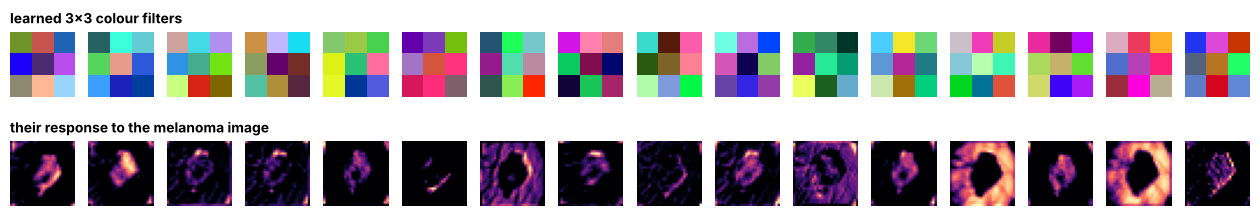

In [9]:
# What did the first layer learn? Its 16 filters, and their responses to one image
W1 = model.features[0].weight.detach().numpy()          # 16 filters x 3 colours x 3 x 3
fig, axes = plt.subplots(2, 16, figsize=(16, 2.6))
with torch.no_grad():
    maps = model.features[:3](T["train"][[np.where(data["train"]["cls"] == 4)[0][3]]])[0].numpy()
for k in range(16):
    f = W1[k].transpose(1, 2, 0); f = (f - f.min()) / (f.max() - f.min() + 1e-9)
    axes[0, k].imshow(f); axes[0, k].axis("off")
    axes[1, k].imshow(maps[k], cmap="magma"); axes[1, k].axis("off")
axes[0, 0].set_title("learned 3x3 colour filters", loc="left", fontsize=10)
axes[1, 0].set_title("their response to the melanoma image", loc="left", fontsize=10)
plt.show()

**What this shows:** some first-layer maps highlight the lesion, its border or nearby skin in this example. The network learned these responses from training images. A single map does not prove what clinical feature a filter represents. Later layers combine many maps, making their role harder to explain by looking at them

# 4. Is the test really independent?

HAM10000 often has several photos of the same lesion, taken at different angles or magnifications. If one photo is used for training and another for testing, the test includes a lesion the model has already seen

This is **data leakage**: training and test information overlap in a way that weakens the test. The original DermaMNIST split separated images without keeping all photos of each lesion together. The corrected version fixes this lesion overlap. First, we count it

Original DermaMNIST: 693 of 2005 test images (35%) show a lesion that also appears in training
Corrected DermaMNIST: 0 test images share a lesion with training


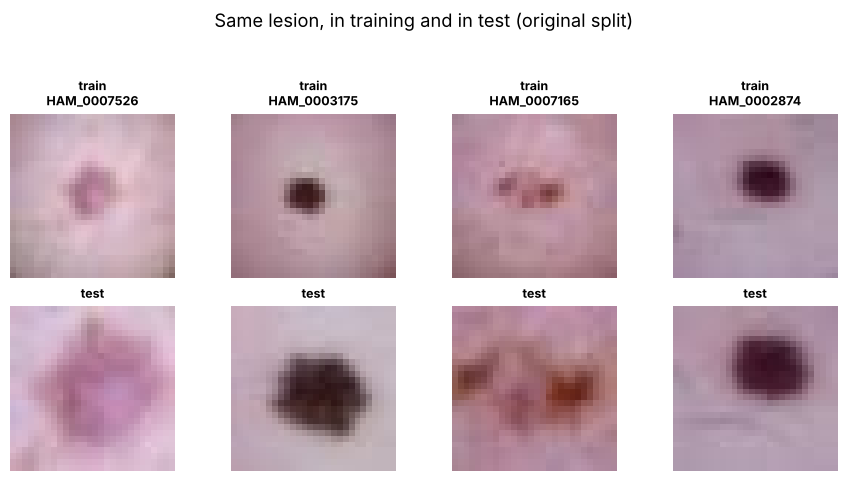

In [10]:
split_o = pd.read_csv(fetch("split_original")).merge(pd.read_csv(fetch("ham_meta")), on="image_id")
train_lesions = set(split_o[split_o.split == "train"].lesion_id)
test_o = split_o[split_o.split == "test"]
shared = test_o.lesion_id.isin(train_lesions)
print(f"Original DermaMNIST: {shared.sum()} of {len(test_o)} test images ({shared.mean():.0%}) show a lesion that also appears in training")
corr = allmeta
print(f"Corrected DermaMNIST: {corr[corr.set == 'test'].lesion_id.isin(set(corr[corr.set == 'train'].lesion_id)).sum()} test images share a lesion with training")

# Show three lesions that appear in both original training and test sets
ex = test_o[shared].drop_duplicates("lesion_id").head(4)
orig = np.load(fetch("original"))
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for c, (_, r) in enumerate(ex.iterrows()):
    tr_row = split_o[(split_o.lesion_id == r.lesion_id) & (split_o.split == "train")].iloc[0]
    axes[0, c].imshow(orig["train_images"][tr_row["index"]]); axes[0, c].set_title(f"train\n{r.lesion_id}", fontsize=9)
    axes[1, c].imshow(orig["test_images"][r["index"]]); axes[1, c].set_title("test", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("Same lesion, in training and in test (original split)", y=1.04); plt.tight_layout(); plt.show()

**What this shows**

- In the original split, 693 of 2,005 test images, about 35%, show a lesion also present in training
- The corrected split has no test lesion identifiers shared with training
- The original test did not measure performance only on new lesions. Its 2,005 images also should not be treated as 2,005 independent lesions when estimating uncertainty

These checks use lesion identifiers. They cannot establish patient independence because patient identifiers are unavailable

## 4.1 How much does leakage change the score? A controlled comparison

This optional live section takes about 2 min on the previously tested setup. Later section 4.2 uses its results, so run it in order or read the saved outputs

1. Set aside 20% of lesions. Keep one photo per held-out lesion for testing. Call any other photos of those lesions **additional photos**
2. **Clean training:** use only the remaining lesions, reserving some for validation
3. **Training with leakage:** replace randomly selected training images with the additional photos of test lesions. Keep training size, validation images and test images fixed
4. Train the same network structure under both conditions and compare scores. Repeat for two random seeds

This comparison keeps the test images fixed. Replacing training images also changes the training mix, which limits how completely we can isolate the effect of overlap

In [11]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split
Xall = np.concatenate([data[s]["X"] for s in data]); yall = np.concatenate([data[s]["y"] for s in data])
gall = np.concatenate([data[s]["meta"].lesion_id.values for s in data])
rows = []
for seed in [0, 1]:
    rng_l = np.random.default_rng(seed)
    pool_tr, pool_te = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(Xall, yall, gall))
    held = pd.DataFrame({"i": pool_te, "g": gall[pool_te]}).sample(frac=1, random_state=seed)
    test_idx = held.drop_duplicates("g").i.values                       # one photo per held-out lesion
    siblings = np.setdiff1d(pool_te, test_idx)                           # the other photos of those lesions
    has_sib = np.isin(gall[test_idx], gall[siblings])
    in_tr, in_va = next(GroupShuffleSplit(1, test_size=0.1, random_state=seed).split(pool_tr, groups=gall[pool_tr]))
    clean_tr, va = pool_tr[in_tr], pool_tr[in_va]
    leaky_tr = np.concatenate([np.setdiff1d(clean_tr, rng_l.choice(clean_tr, len(siblings), replace=False)), siblings])
    for name, a in {"clean training": clean_tr, "leaky training": leaky_tr}.items():
        m, (mu_, sd_), _ = train_cnn(Xall[a], yall[a], Xall[va], yall[va], seed=seed, verbose=False)
        pt = predict_cnn(m, to_tensor(Xall[test_idx], mu_, sd_)); yy = yall[test_idx]
        rows.append({"seed": seed, "training": name, "training images": len(a), "test images": len(test_idx),
                     "AUROC, all test images": roc_auc_score(yy, pt),
                     f"AUROC, lesions with a sibling": roc_auc_score(yy[has_sib], pt[has_sib]),
                     "AUROC, lesions without": roc_auc_score(yy[~has_sib], pt[~has_sib])})
    print(f"seed {seed}: {len(siblings)} sibling photos; {has_sib.sum()} of {len(test_idx)} test lesions have a sibling")
leak = pd.DataFrame(rows); display(leak.round(3))
les_te = test_idx                                                          # used in section 4.2

seed 0: 512 sibling photos; 387 of 1494 test lesions have a sibling


seed 1: 554 sibling photos; 417 of 1494 test lesions have a sibling


,seed,training,training images,test images,"AUROC, all test images","AUROC, lesions with a sibling","AUROC, lesions without"
0,0,clean training,7194,1494,0.904,0.717,0.957
1,0,leaky training,7194,1494,0.908,0.715,0.961
2,1,clean training,7157,1494,0.899,0.733,0.945
3,1,leaky training,7157,1494,0.898,0.743,0.941


**What this shows** (table above)

- With the same test images and training size, the network trained with leakage scores 0.908 against 0.904 for seed 0, and 0.898 against 0.899 for seed 1
- Among test lesions with another photo in training, the differences are -0.002 and +0.010. These two runs show no consistent improvement from leakage; they do not establish that leakage has no effect
- Both models rank lesions with additional photos less well: AUROC is about 0.72 to 0.74, against 0.94 to 0.96 for lesions photographed only once. The next cell compares these groups
- Overlap still makes the test unsuitable for assessing performance only on new lesions, even when the score changes little

> **Practical rule:** keep all images from one patient in the same split where possible. If patient identifiers are unavailable, keep each lesion together and state the remaining limit

In [12]:
# Why are the shared-lesion images harder? Compare lesions photographed once with lesions photographed several times
ham = pd.read_csv(fetch("ham_meta"))
ham["photos_of_lesion"] = np.where(ham.groupby("lesion_id").image_id.transform("size") > 1, "several photos", "one photo")
ham["possibly_cancerous"] = ham.dx.isin(["mel", "bcc", "akiec"])
ham["confirmed_by_biopsy"] = ham.dx_type.eq("histo")
display((100 * ham.groupby("photos_of_lesion")[["possibly_cancerous", "confirmed_by_biopsy"]].mean()).round(0).astype(int).astype(str) + "%")

,possibly_cancerous,confirmed_by_biopsy
photos_of_lesion,,
one photo,10%,25%
several photos,31%,88%


**What this shows:** lesions photographed several times differ from those photographed once. About 31% belong to the possibly cancerous group, compared with 10%; about 88% were confirmed by biopsy, compared with 25%. A biopsy examines a tissue sample under a microscope. These differences may help explain the lower ranking scores, but we have not tested why those lesions are harder for the model

## 4.2 Same network structure, different test results

Neither our lesion-based split nor the official corrected split shares lesions between training and testing. Yet networks trained and tested on these different splits get different scores. We compare the diagnoses in their test sets

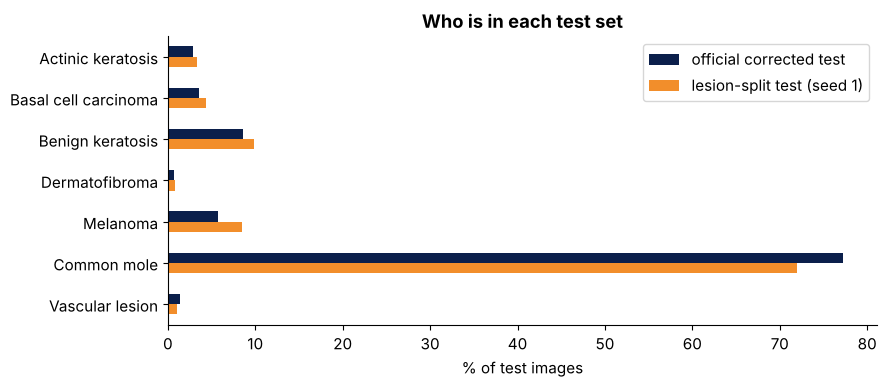

Possibly cancerous: official test 12.1% | lesion-split test 16.3%


In [13]:
lesion_test_cls = np.concatenate([data[s]["cls"] for s in data])[les_te]   # seed 1 test images from section 4.1
comp = pd.DataFrame({"official corrected test": pd.Series(data["test"]["cls"]).value_counts(normalize=True),
                     "lesion-split test (seed 1)": pd.Series(lesion_test_cls).value_counts(normalize=True)}).sort_index()
comp.index = [CLASSES[k].split(" (")[0] for k in comp.index]
ax = (100 * comp).plot.barh(figsize=(9, 4), color=[NAVY, ORANGE]); ax.invert_yaxis()
ax.set_xlabel("% of test images"); ax.set_title("Who is in each test set"); plt.tight_layout(); plt.show()
print(f"Possibly cancerous: official test {100*data['test']['y'].mean():.1f}% | lesion-split test {100*yall[les_te].mean():.1f}%")

**What this shows** (output above)

- The test set from section 4.1 contains 16.3% possibly cancerous images; the official corrected test set contains 12.1%
- Networks trained on those different splits score about 0.90 and 0.944 on their respective test sets. The diagnoses, particular lesions, source collections and training samples differ, so this comparison cannot isolate one cause
- AUROC depends on which kinds of positive and negative cases are tested. A higher positive share alone does not explain a lower AUROC

> **Practical action:** test the model in the intended clinic. Results from one mix of lesions do not establish performance on a different mix

# 5. Check changes to training images

**Data augmentation** creates training variations by changing images, for example rotating them. The diagnosis should stay the same, and the image must retain enough useful information for that diagnosis

| Change | What to check | Choice for this exercise |
|---|---|---|
| Mirror or rotate by 90 degrees | These dermatoscope lesions have no fixed viewing direction | Use |
| Small brightness change | Keep important detail visible | Use with care |
| Strong colour shift | Can distort colours used to assess lesions | Avoid |
| Grey scale | Removes colour information used in assessment | Avoid |
| Heavy crop | Can remove the lesion border or other important detail | Avoid |

These changes do not alter the patient's disease. The concern is whether the altered image still supports the same interpretation

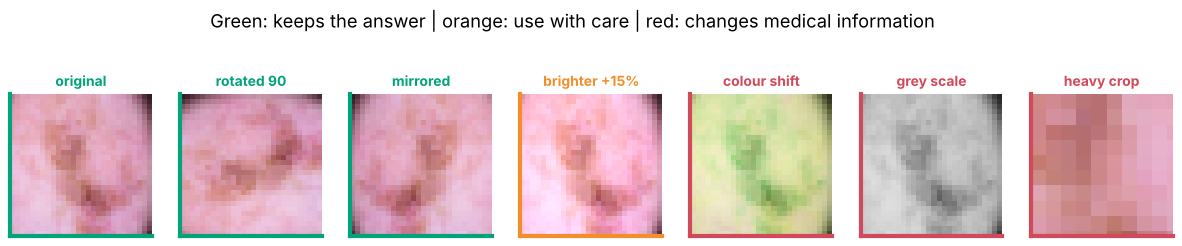

trained 15 epochs in 18 s, best validation AUROC 0.961
Test AUROC  with mirror/rotate augmentation 0.944 | without 0.951


In [14]:
import colorsys
im = data["train"]["X"][np.where(data["train"]["cls"] == 4)[0][7]] / 255.0
def hue_shift(a, d): h = np.vectorize(colorsys.rgb_to_hsv)(a[..., 0], a[..., 1], a[..., 2]); return np.stack(np.vectorize(colorsys.hsv_to_rgb)((h[0] + d) % 1, h[1], h[2]), -1)
views = {"original": im, "rotated 90": np.rot90(im), "mirrored": im[:, ::-1], "brighter +15%": np.clip(im * 1.15, 0, 1),
         "colour shift": hue_shift(im, 0.25), "grey scale": np.repeat(im.mean(2, keepdims=True), 3, 2), "heavy crop": np.kron(im[9:19, 9:19], np.ones((3, 3, 1)))[:28, :28]}
ok = {"original": GREEN, "rotated 90": GREEN, "mirrored": GREEN, "brighter +15%": ORANGE, "colour shift": RED, "grey scale": RED, "heavy crop": RED}
fig, axes = plt.subplots(1, 7, figsize=(15, 2.8))
for ax, (k, v) in zip(axes, views.items()):
    ax.imshow(v); ax.set_title(k, color=ok[k], fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_edgecolor(ok[k]); s.set_linewidth(3)
fig.suptitle("Green: keeps the answer | orange: use with care | red: changes medical information", y=1.05); plt.show()

m_noaug, (mu_n, sd_n), _ = train_cnn(data["train"]["X"], data["train"]["y"], data["val"]["X"], data["val"]["y"], use_augment=False, seed=0)
p_noaug = predict_cnn(m_noaug, to_tensor(data["test"]["X"], mu_n, sd_n))
print(f"Test AUROC  with mirror/rotate augmentation {roc_auc_score(yte, p_cnn):.3f} | without {roc_auc_score(yte, p_noaug):.3f}")

**What this shows** (output above)

- Mirroring and rotation do not improve AUROC in this comparison: 0.944 with them, 0.951 without them
- We ran each setting once. These results do not establish that either setting is generally better
- A score increase alone would not justify changes that remove useful clinical information

> **Practical check:** ask a clinician whether an image change preserves the information needed for the task, then test whether it helps the model

# 6. Takeaways

**Key insights**

- This small CNN ranks skin images better than logistic regression on raw pixels
- Missing skin-tone information prevents a performance comparison across skin tones
- Separate patients, or at least lesions, between training and testing; report what cannot be checked
- A test score describes a model on a particular set of cases

**Common pitfalls**

- Splitting images without keeping photos of the same lesion together
- Comparing scores from different test sets as if they came from the same experiment
- Changing training images in ways that remove useful medical information

**What this means for healthcare decision makers**

- Ask how the data were split, which diagnoses they include and which groups cannot be assessed
- Request testing on data from the intended care setting

**Next session:** use explanation maps to investigate image models and check whether the maps are reliable

**Check your understanding**

1. Why can the same filter respond to a border in different parts of an image?
2. Why might an image change be acceptable for one medical task but unsuitable for another? Give an example
3. Two papers report AUROC scores of 0.95 and 0.86 for similar models. What would you check before calling one better?